<a href="https://colab.research.google.com/github/vothitrangtho27-sketch/HocMayBuoi1/blob/main/HocMayBuoi1_VoThiTrangTho.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Ví dụ: dữ liệu ngẫu nhiên (hoặc dữ liệu thực tế) để dự đoán mối quan hệ giữa hai biến.**

Hệ số chặn (Intercept): [4.20634019]
Hệ số góc (Slope): [[2.9902591]]
Mean Squared Error (MSE): 0.9177532469714291
R^2 score: 0.6521157503858556


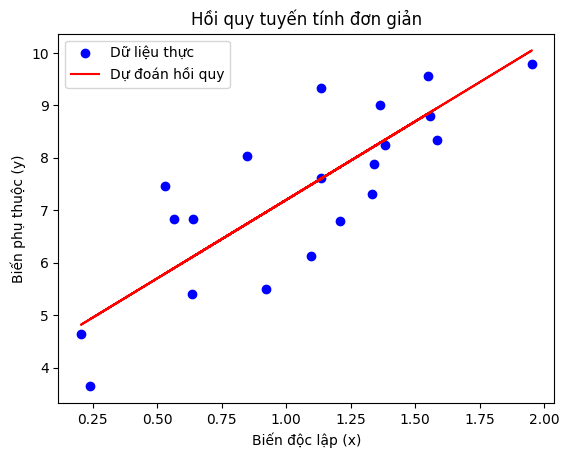

In [18]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
np.random.seed(0)
x = 2 * np.random.rand(100, 1)
y = 4 + 3 * x + np.random.randn(100, 1)
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2,random_state=42)
model = LinearRegression()
model.fit(x_train, y_train)
y_pred = model.predict(x_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f"Hệ số chặn (Intercept): {model.intercept_}")
print(f"Hệ số góc (Slope): {model.coef_}")
print(f"Mean Squared Error (MSE): {mse}")
print(f"R^2 score: {r2}")
plt.scatter(x_test, y_test, color="blue", label="Dữ liệu thực")
plt.plot(x_test, y_pred, color="red", label="Dự đoán hồi quy")
plt.title("Hồi quy tuyến tính đơn giản")
plt.xlabel("Biến độc lập (x)")
plt.ylabel("Biến phụ thuộc (y)")
plt.legend()
plt.show()

# **Ví dụ: với dữ liệu có nhiều biến đầu vào:**

In [2]:

import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
np.random.seed(0)
X = 2 * np.random.rand(100, 3)
y = 4 + 3 * X[:, 0] + 2 * X[:, 1] + 5 * X[:, 2] + np.random.randn(100, 1)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
random_state=42)
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
print(f"Hệ số chặn (Intercept): {model.intercept_}")
print(f"Hệ số hồi quy (Coefficients): {model.coef_}")
print(f"Mean Squared Error (MSE): {mse}")

Hệ số chặn (Intercept): [16.19760926 15.43919644 19.84557989 14.77283548 11.83735151 12.94618486
 21.95150953 18.46249761  8.71920053 15.9183632  13.26210877 13.67845488
 19.59412812 13.91560995 15.11069323 10.17095745 13.06571791 11.62188955
 12.44591888  9.84558564 11.97495097  9.31901587 17.71015057 13.18527734
 19.68892141  6.58465723  9.44792087 13.68322616 13.70998424 16.17672804
  9.91537087 11.30383823 15.9052451   9.45585575 14.76378676 15.5639678
 13.63707664 14.86707566 19.29617887 17.9562316  19.93399657 15.63963054
 11.93953084 12.51655138 11.72195981 16.39088277 18.62009633 16.88440148
 12.67132415 22.37866796 10.01046042 16.68505662 15.20848669 11.7564809
 21.56941496 12.79779405 14.29316516  5.32756899 13.12773879 12.72087168
 13.26270144 15.32020949 16.89099403  9.57932872 16.30649256 10.41231319
  9.2201373  11.50144208 11.22733564 17.85154785 17.45674067 13.26266181
 13.35346663 20.24506167 10.706136   14.63811683 15.16340021  7.62563891
 10.70159914 13.77614785 14.8

# **Hồi quy Logistic với bộ dữ liệu hoa Iris:**

In [11]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix,classification_report
iris = load_iris()
X = iris['data']
y = iris['target']
X = X[y != 2]
y = y[y != 2]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
random_state=42)
model = LogisticRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)
print(f"Độ chính xác (Accuracy): {accuracy}")
print("Ma trận nhầm lẫn (Confusion Matrix):")
print(conf_matrix)
print("Báo cáo phân loại (Classification Report):")
print(class_report)

Độ chính xác (Accuracy): 1.0
Ma trận nhầm lẫn (Confusion Matrix):
[[12  0]
 [ 0  8]]
Báo cáo phân loại (Classification Report):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       1.00      1.00      1.00         8

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20



**Bài 1. Giả sử có một tập dữ liệu giả định với các cột Diện tích nhà (m2) và Giá bán (triệu VND).**
1. Cần xây dựng một mô hình hồi quy tuyến tính đơn giản để dự đoán Giá bán dựa trên
Diện tích nhà.
2. Thêm nhiều (số lượng) dữ liệu và độ nhiễu để xem mô hình hoạt động như thế nào.
3. Thêm các biến đầu vào khác để nâng cao tính phức tạp của mô hình.

PHẦN 1: HỒI QUY TUYẾN TÍNH ĐƠN GIẢN
Hệ số chặn (Intercept): 236.49
Hệ số góc (Slope - Giá trung bình tăng thêm mỗi m2): 14.50
Mean Squared Error (MSE): 14708.24
R2 Score: 0.9507


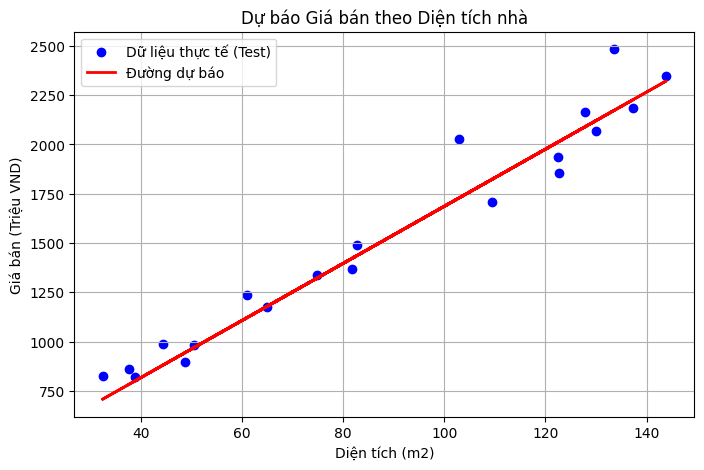

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
np.random.seed(42)
dien_tich = 30 + 120 * np.random.rand(100, 1)
gia_ban = 15 * dien_tich + 200 + np.random.randn(100, 1) * 150
X_train, X_test, y_train, y_test = train_test_split(dien_tich, gia_ban, test_size=0.2, random_state=42)
simple_model = LinearRegression()
simple_model.fit(X_train, y_train)
y_pred = simple_model.predict(X_test)
mse_1 = mean_squared_error(y_test, y_pred)
r2_1 = r2_score(y_test, y_pred)
print("PHẦN 1: HỒI QUY TUYẾN TÍNH ĐƠN GIẢN")
print(f"Hệ số chặn (Intercept): {simple_model.intercept_[0]:.2f}")
print(f"Hệ số góc (Slope - Giá trung bình tăng thêm mỗi m2): {simple_model.coef_[0][0]:.2f}")
print(f"Mean Squared Error (MSE): {mse_1:.2f}")
print(f"R2 Score: {r2_1:.4f}")
plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, color='blue', label='Dữ liệu thực tế (Test)')
plt.plot(X_test, y_pred, color='red', linewidth=2, label='Đường dự báo')
plt.title('Dự báo Giá bán theo Diện tích nhà')
plt.xlabel('Diện tích (m2)')
plt.ylabel('Giá bán (Triệu VND)')
plt.legend()
plt.grid(True)
plt.show()

In [15]:

np.random.seed(42)
n_samples = 1000
dien_tich_large = 30 + 120 * np.random.rand(n_samples, 1)
gia_ban_noisy = 15 * dien_tich_large + 200 + np.random.randn(n_samples, 1) * 400
X_train_l, X_test_l, y_train_l, y_test_l = train_test_split(dien_tich_large, gia_ban_noisy, test_size=0.2, random_state=42)
large_model = LinearRegression()
large_model.fit(X_train_l, y_train_l)
y_pred_l = large_model.predict(X_test_l)
mse_2 = mean_squared_error(y_test_l, y_pred_l)
r2_2 = r2_score(y_test_l, y_pred_l)
print("PHẦN 2: THỬ NGHIỆM TĂNG QUY MÔ & TĂNG ĐỘ NHIỄU ")
print(f"Số lượng mẫu: {n_samples}")
print(f"Hệ số chặn (Intercept): {large_model.intercept_[0]:.2f}")
print(f"Hệ số góc (Slope): {large_model.coef_[0][0]:.2f}")
print(f"Mean Squared Error (MSE) - Tăng do nhiều nhiễu: {mse_2:.2f}")
print(f"R2 Score (Độ giải thích của mô hình bị giảm khi nhiễu lớn): {r2_2:.4f}")

PHẦN 2: THỬ NGHIỆM TĂNG QUY MÔ & TĂNG ĐỘ NHIỄU 
Số lượng mẫu: 1000
Hệ số chặn (Intercept): 293.53
Hệ số góc (Slope): 14.41
Mean Squared Error (MSE) - Tăng do nhiều nhiễu: 137179.59
R2 Score (Độ giải thích của mô hình bị giảm khi nhiễu lớn): 0.6555


In [17]:

np.random.seed(42)
X_multi = np.zeros((200, 3))
X_multi[:, 0] = (30 + 120 * np.random.rand(200))
X_multi[:, 1] = np.random.randint(1, 6, size=200)
X_multi[:, 2] = (1 + 19 * np.random.rand(200))
y_multi = (12 * X_multi[:, 0] + 150 * X_multi[:, 1] - 40 * X_multi[:, 2] + 300
           + np.random.randn(200) * 80)
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(X_multi, y_multi, test_size=0.2, random_state=42)
multi_model = LinearRegression()
multi_model.fit(X_train_m, y_train_m)
y_pred_m = multi_model.predict(X_test_m)
mse_3 = mean_squared_error(y_test_m, y_pred_m)
r2_3 = r2_score(y_test_m, y_pred_m)

print("PHẦN 3: HỒI QUY ĐA BIẾN (DIỆN TÍCH, SỐ PHÒNG, KHOẢNG CÁCH)")
print(f"Hệ số chặn (Intercept): {multi_model.intercept_:.2f}")
print(f"Các hệ số hồi quy tương ứng (Coefficients): {multi_model.coef_}")
print(f"  - Tác động của Diện tích: {multi_model.coef_[0]:.2f}")
print(f"  - Tác động của Số phòng ngủ: {multi_model.coef_[1]:.2f}")
print(f"  - Tác động của Khoảng cách: {multi_model.coef_[2]:.2f}")
print(f"Mean Squared Error (MSE): {mse_3:.2f}")
print(f"R2 Score (Độ chính xác cao hơn nhờ nhiều biến đặc trưng bổ trợ): {r2_3:.4f}")

PHẦN 3: HỒI QUY ĐA BIẾN (DIỆN TÍCH, SỐ PHÒNG, KHOẢNG CÁCH)
Hệ số chặn (Intercept): 324.57
Các hệ số hồi quy tương ứng (Coefficients): [ 11.79351124 151.96183662 -41.40828841]
  - Tác động của Diện tích: 11.79
  - Tác động của Số phòng ngủ: 151.96
  - Tác động của Khoảng cách: -41.41
Mean Squared Error (MSE): 4347.52
R2 Score (Độ chính xác cao hơn nhờ nhiều biến đặc trưng bổ trợ): 0.9828


Bài 2. Dự đoán khả năng mắc bệnh dựa trên chỉ số BMI
Giả sử có một tập dữ liệu với các thông tin sau: **văn bản in đậm**
- BMI: Chỉ số khối cơ thể của bệnh nhân (Body Mass Index).
- Mắc bệnh: Nhãn mục tiêu là 1 nếu bệnh nhân mắc bệnh và 0 nếu không mắc bệnh.
Yêu cầu:
1. - Tạo dữ liệu mẫu giả lập với đặc trưng BMI và nhãn Mắc bệnh dựa trên mối liên hệ logic
(BMI cao có thể dẫn đến khả năng mắc bệnh cao hơn).
2. - Sử dụng thư viện phù hợp (HD: scikit-learn) để xây dựng một mô hình hồi quy logistic.
3. - Huấn luyện mô hình trên tập dữ liệu mẫu.
4. - Dự đoán xác suất và nhãn mắc bệnh cho một tập dữ liệu kiểm tra.
5. - Đánh giá hiệu quả của mô hình thông qua độ chính xác và ma trận nhầm lẫn.
6. - Trực quan hóa dữ liệu và đường hồi quy logistic.
Bài 3. Hãy chọn 1 bộ dữ liệu tùy ý (HD: có thể tham khảo trên các trang mạng, ví dụ như
Kaggle) và thực hiện các bước cần thiết để có được mô hình hồi qui ứng với bộ dữ liệu đã
chọn.

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
np.random.seed(42)
n_samples = 150
bmi = 18 + 17 * np.random.rand(n_samples, 1)
logits = 0.8 * (bmi - 26)
probabilities = 1 / (1 + np.exp(-logits))
mac_benh = np.random.binomial(1, probabilities).reshape(-1)
X_train, X_test, y_train, y_test = train_test_split(bmi, mac_benh, test_size=0.2, random_state=42)

In [20]:

model_logistic = LogisticRegression()
model_logistic.fit(X_train, y_train)
y_pred = model_logistic.predict(X_test)
y_prob = model_logistic.predict_proba(X_test)[:, 1]

In [21]:

accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)

print("=== KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH ===")
print(f"Độ chính xác (Accuracy): {accuracy:.2f} ({accuracy * 100:.1f}%)")
print("\nMa trận nhầm lẫn (Confusion Matrix):")
print(conf_matrix)
print("\nBáo cáo phân loại (Classification Report):")
print(class_report)

=== KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH ===
Độ chính xác (Accuracy): 0.97 (96.7%)

Ma trận nhầm lẫn (Confusion Matrix):
[[18  0]
 [ 1 11]]

Báo cáo phân loại (Classification Report):
              precision    recall  f1-score   support

           0       0.95      1.00      0.97        18
           1       1.00      0.92      0.96        12

    accuracy                           0.97        30
   macro avg       0.97      0.96      0.96        30
weighted avg       0.97      0.97      0.97        30



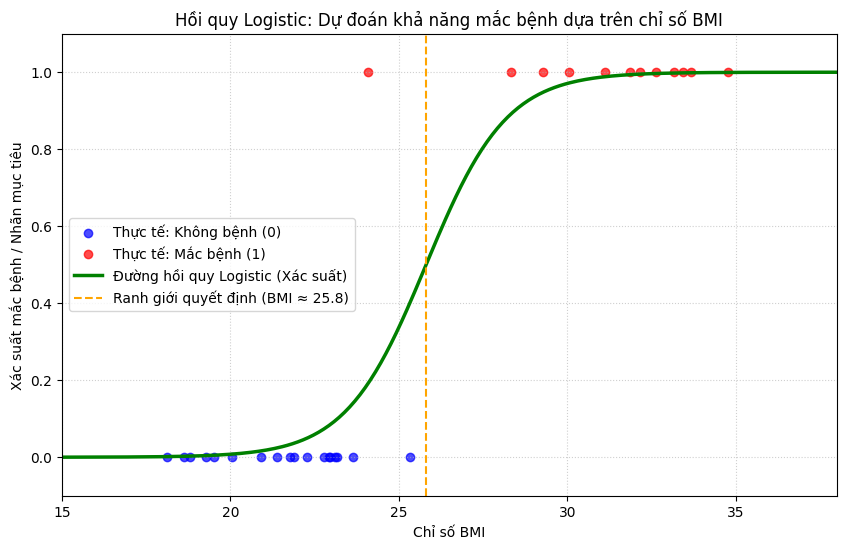

In [22]:

X_curve = np.linspace(15, 38, 300).reshape(-1, 1)
y_curve_prob = model_logistic.predict_proba(X_curve)[:, 1]

plt.figure(figsize=(10, 6))
plt.scatter(X_test[y_test == 0], y_test[y_test == 0], color='blue', alpha=0.7, label='Thực tế: Không bệnh (0)')
plt.scatter(X_test[y_test == 1], y_test[y_test == 1], color='red', alpha=0.7, label='Thực tế: Mắc bệnh (1)')
plt.plot(X_curve, y_curve_prob, color='green', linewidth=2.5, label='Đường hồi quy Logistic (Xác suất)')
decision_boundary = -model_logistic.intercept_[0] / model_logistic.coef_[0][0]
plt.axvline(x=decision_boundary, color='orange', linestyle='--', label=f'Ranh giới quyết định (BMI ≈ {decision_boundary:.1f})')

plt.title('Hồi quy Logistic: Dự đoán khả năng mắc bệnh dựa trên chỉ số BMI')
plt.xlabel('Chỉ số BMI')
plt.ylabel('Xác suất mắc bệnh / Nhãn mục tiêu')
plt.legend(loc='center left')
plt.grid(True, linestyle=':', alpha=0.6)
plt.xlim(15, 38)
plt.ylim(-0.1, 1.1)
plt.show()

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

data_path = '/content/sample_data/california_housing_train.csv'
df = pd.read_csv(data_path)

print("=== THÔNG TIN BỘ DỮ LIỆU CALIFORNIA HOUSING ===")
print(f"Kích thước tập dữ liệu: {df.shape[0]} dòng, {df.shape[1]} cột")
print("\n5 dòng dữ liệu đầu tiên:")
display(df.head())

=== THÔNG TIN BỘ DỮ LIỆU CALIFORNIA HOUSING ===
Kích thước tập dữ liệu: 17000 dòng, 9 cột

5 dòng dữ liệu đầu tiên:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-114.31,34.19,15.0,5612.0,1283.0,1015.0,472.0,1.4936,66900.0
1,-114.47,34.40,19.0,7650.0,1901.0,1129.0,463.0,1.8200,80100.0
2,-114.56,33.69,17.0,720.0,174.0,333.0,117.0,1.6509,85700.0
3,-114.57,33.64,14.0,1501.0,337.0,515.0,226.0,3.1917,73400.0
4,-114.57,33.57,20.0,1454.0,326.0,624.0,262.0,1.9250,65500.0


In [26]:

X_housing = df.drop(columns=['median_house_value'])
y_housing = df['median_house_value']
X_train_h, X_test_h, y_train_h, y_test_h = train_test_split(X_housing, y_housing, test_size=0.2, random_state=42)
housing_model = LinearRegression()
housing_model.fit(X_train_h, y_train_h)
y_pred_h = housing_model.predict(X_test_h)
mse_h = mean_squared_error(y_test_h, y_pred_h)
r2_h = r2_score(y_test_h, y_pred_h)

print("=== KẾT QUẢ HUẤN LUYỆN MÔ HÌNH HỒI QUY ===")
print(f"Hệ số chặn (Intercept): {housing_model.intercept_:.2f}")
print("Hệ số hồi quy cho từng đặc trưng (Coefficients):")
for col, coef in zip(X_housing.columns, housing_model.coef_):
    print(f"  - {col}: {coef:.2f}")

print(f"\nMean Squared Error (MSE): {mse_h:.2f}")
print(f"R^2 Score (Hệ số xác định): {r2_h:.4f}")

=== KẾT QUẢ HUẤN LUYỆN MÔ HÌNH HỒI QUY ===
Hệ số chặn (Intercept): -3652253.13
Hệ số hồi quy cho từng đặc trưng (Coefficients):
  - longitude: -43465.25
  - latitude: -43106.30
  - housing_median_age: 1131.72
  - total_rooms: -8.84
  - total_bedrooms: 113.71
  - population: -35.66
  - households: 45.15
  - median_income: 40194.73

Mean Squared Error (MSE): 4634658406.22
R^2 Score (Hệ số xác định): 0.6636


/tmp/ipykernel_1020/2616396561.py:5: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k--" (-> color='k'). The keyword argument will take precedence.
  plt.plot([y_test_h.min(), y_test_h.max()], [y_test_h.min(), y_test_h.max()], 'k--', lw=2, color='red', label='Đường lý tưởng')


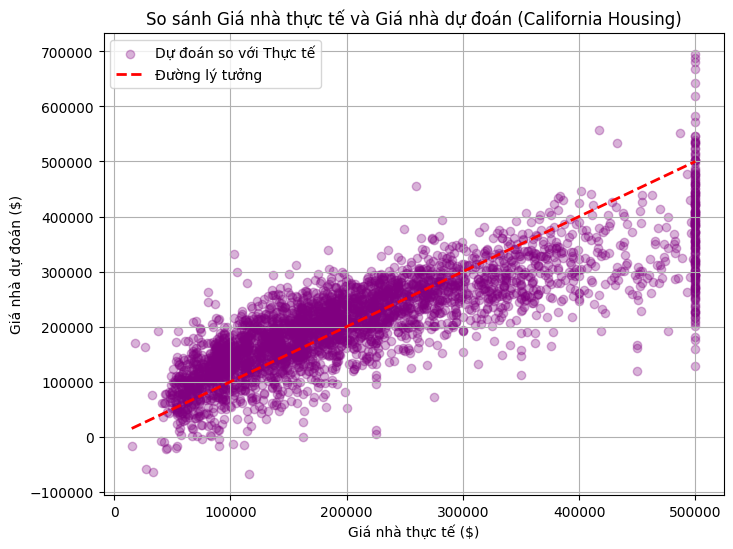

In [27]:

plt.figure(figsize=(8, 6))
plt.scatter(y_test_h, y_pred_h, color='purple', alpha=0.3, label='Dự đoán so với Thực tế')
plt.plot([y_test_h.min(), y_test_h.max()], [y_test_h.min(), y_test_h.max()], 'k--', lw=2, color='red', label='Đường lý tưởng')
plt.title('So sánh Giá nhà thực tế và Giá nhà dự đoán (California Housing)')
plt.xlabel('Giá nhà thực tế ($)')
plt.ylabel('Giá nhà dự đoán ($)')
plt.legend()
plt.grid(True)
plt.show()